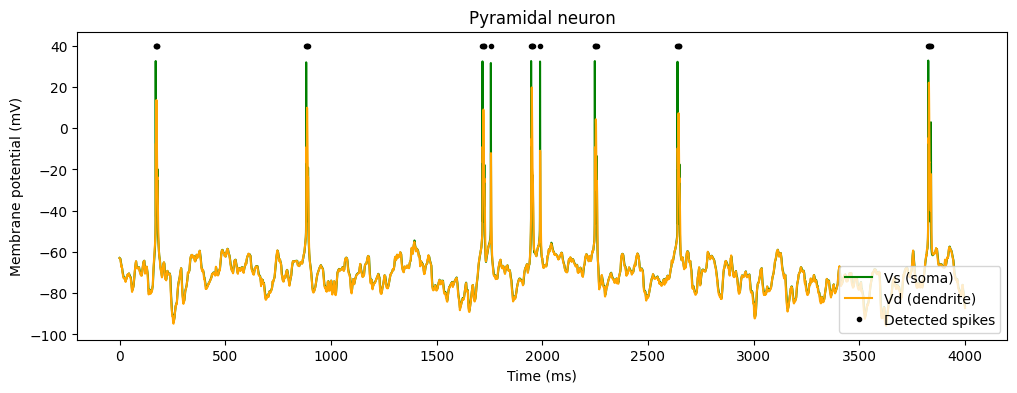

In [1]:
import matplotlib.pyplot as plt

from neural_recording_chain.frozen_noise import make_frozen_noise
from neural_recording_chain.pyramidal_cell import simulate_pyramidal_cell

input_theory, hidden_state = make_frozen_noise(duration_ms=4000, dt_ms=0.05, seed=0)
result = simulate_pyramidal_cell(input_theory, dt_ms=0.05)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(result["time_ms"], result["v_soma_mV"], color="green", label="Vs (soma)")
ax.plot(result["time_ms"], result["v_dend_mV"], color="orange", label="Vd (dendrite)")
ax.plot(result["spike_times_ms"], [40] * len(result["spike_times_ms"]), "k.", label="Detected spikes")
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Membrane potential (mV)")
ax.set_title("Pyramidal neuron")
ax.legend(loc="lower right")
plt.show()

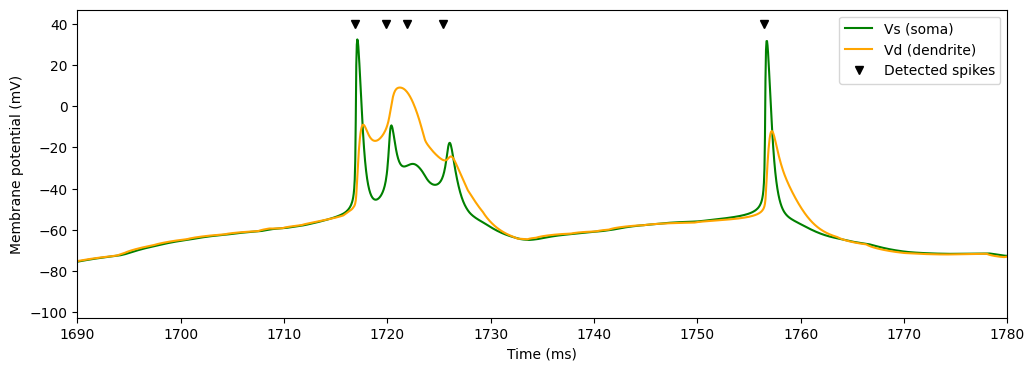

In [2]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(result["time_ms"], result["v_soma_mV"], color="green", label="Vs (soma)")
ax.plot(result["time_ms"], result["v_dend_mV"], color="orange", label="Vd (dendrite)")
ax.plot(result["spike_times_ms"], [40] * len(result["spike_times_ms"]), "kv", label="Detected spikes")
ax.set_xlim(1690, 1780)
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Membrane potential (mV)")
ax.legend(loc="upper right")
plt.show()

In [3]:
from neural_recording_chain.spikes import find_spikes

spike_times, spike_heights = find_spikes(result["v_soma_mV"], result["time_ms"])
print("old counter:", len(result["spike_times_ms"]))
print("new finder: ", len(spike_times))

in_window = (spike_times > 1690) & (spike_times < 1780)
print(spike_times[in_window].round(1))
print(spike_heights[in_window].round(1))

old counter: 31
new finder:  24
[1717.1 1720.4 1726.  1756.8]
[ 32.4  -9.3 -17.7  31.6]


lowest:  -288.5 uV
highest: 186.5 uV


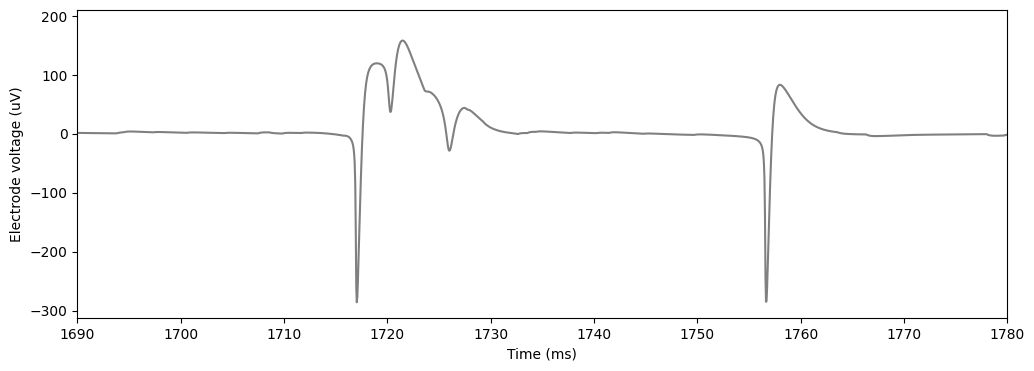

In [4]:
from neural_recording_chain.electrode import extracellular_potential

v_electrode_uV = extracellular_potential(result["v_soma_mV"], result["v_dend_mV"])
print("lowest: ", v_electrode_uV.min().round(1), "uV")
print("highest:", v_electrode_uV.max().round(1), "uV")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(result["time_ms"], v_electrode_uV, color="grey")
ax.set_xlim(1690, 1780)
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Electrode voltage (uV)")
plt.show()

noise size: 13.1 uV


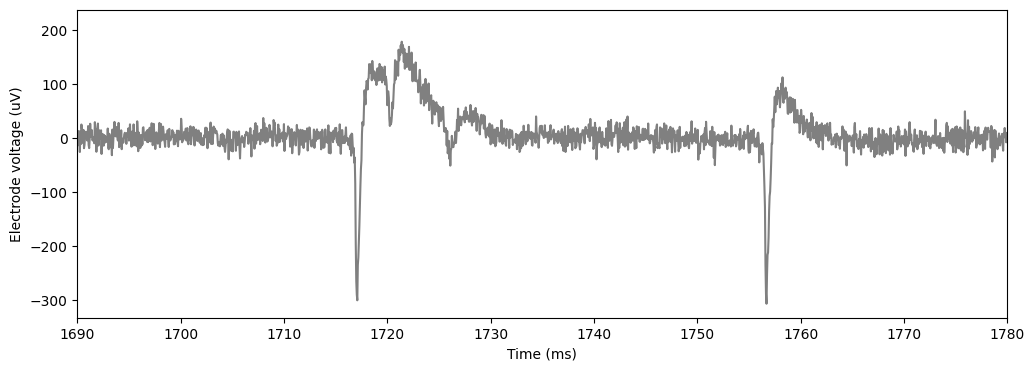

In [5]:
from neural_recording_chain.noise import thermal_noise_uV

noise = thermal_noise_uV(len(v_electrode_uV), dt_ms=0.05)
print("noise size:", noise.std().round(1), "uV")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(result["time_ms"], v_electrode_uV + noise, color="grey")
ax.set_xlim(1690, 1780)
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Electrode voltage (uV)")
plt.show()